## **Setup:**

In [4]:
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

### Helper functions:

In [5]:
def euclidean_distance(a, b):
    """Computes the Euclidean (L2) distance of two vectors: ||a - b||"""
    return np.linalg.norm(a - b, axis=-1)


def assign(X, centers):
    """Returns labels and Euclidean distance from each point to its assigned center: phi_C(x) = argmin_c d(x, c)"""
    D = euclidean_distance(X[:, None, :], centers[None, :, :])
    phi = D.argmin(axis=1)
    return phi, D[np.arange(len(X)), phi]

def cost_2(S, X):
    """Returns the cost of clustering X into C: Cost_2(S, X) = (1 / |X|) sum_x ||x - phi_S(x)||^2"""
    _, d = assign(X, S) 
    return (d ** 2).mean()

### Algorithm functions:

In [6]:
def kmeans_plus_plus(X, k):
    """kmeans++ seeding: next center chosen with probability proportional to its distance to previously chosen centers"""
    centers = [X[0]]
    phi = [0] * len(X)

    for i in range(1, k):
        squared = np.array([euclidean_distance(X[j], centers[phi[j]]) ** 2 for j in range(len(X))])
        probabilities = squared / squared.sum()
        new_center = X[np.random.choice(len(X), p=probabilities)]
        centers.append(new_center)

        for j in range(len(X)):
            if euclidean_distance(X[j], centers[phi[j]]) > euclidean_distance(X[j], new_center):
                phi[j] = i

    return np.array(centers), np.array(phi)

def lloyds(X, centers):
    """Lloyd's algorithm: assign, re-average, repeat until unchanged"""
    while True:
        phi = ((centers ** 2).sum(axis=1) - 2 * X @ centers.T).argmin(axis=1)

        new_centers = np.array([X[phi == i].mean(axis=0) for i in range(len(centers))])

        if np.array_equal(new_centers, centers):
            break
        else:
            centers = new_centers

    return centers, phi

def kmeans(X, k, R):
    """Runs kmeans with Lloyd's algorithm (using kmeans++ initialization)"""
    runs = []

    for _ in range(R):
        centers, phi = kmeans_plus_plus(X, k)
        centers, phi = lloyds(X, centers)
        runs.append((centers, phi))

    return min(runs, key=lambda run: cost_2(run[0], X))

### Cost evaluation functions:

In [7]:
def elbow_method(X):
    """Score cost of clustering X into C: Cost_2(S, X) = (1 / |X|) sum_x ||x - phi_S(x)||^2"""
    costs = []

    for k in range(2, 11):
        c, _ = kmeans(X, k, 10)
        costs.append(cost_2(c, X))

    return costs

def silhouette_score(X, phi):
    """Returns the silhouette score of clustering X: sil(S, X) = (1 / |X|) sum_x (b(x) - a(x)) / max(a(x), b(x))"""
    scores = np.zeros(len(X))
    clusters = np.unique(phi)

    # All pairwise distances at once: ||x - y||^2 = ||x||^2 + ||y||^2 - 2<x, y>
    squared_norms = (X ** 2).sum(axis=1)
    D = np.sqrt(np.maximum(squared_norms[:, None] + squared_norms - 2 * X @ X.T, 0))

    for j in range(len(X)):
        same_cluster = phi == phi[j]

        if same_cluster.sum() == 1:
            continue

        a = D[j][same_cluster].sum() / (same_cluster.sum() - 1)
        b = min(D[j][phi == i].mean() for i in clusters if i != phi[j])
        scores[j] = (b - a) / max(a, b)

    return scores.mean()

## **Build feature matrices:**

### Build matrix 1: reviewers

In [8]:
# Load reviewer_features.csv and set reviewer aside
reviewer_features = pd.read_csv('data/reviewer_features.csv')
reviewers = reviewer_features['reviewer']

# Choose feature columns
X = reviewer_features[['reported_reviews', 'followers','avg_review_length', 'avg_pictures', 'avg_rating']]
X = X.to_numpy(dtype=float)
X = (X - X.mean(axis=0)) / X.std(axis=0)

### Build matrix 2: review text
*(minimal extra cleaning required)*

In [9]:
# Load reviews and drop missing text
restaurant_reviews_cleaned = pd.read_csv('data/restaurant_reviews_cleaned.csv').dropna(subset=['review'])

# Split each review into lowercase letter-only tokens
tokens = restaurant_reviews_cleaned['review'].str.lower().str.findall(r'[a-z]+')

# Keep words that appear in at least 5 reviews
review_counts = Counter(word for words in tokens for word in set(words))
vocabulary = [word for word, count in review_counts.items() if count >= 5]
word_to_column = {word: j for j, word in enumerate(vocabulary)}

# Fill in the word counts
word_counts = np.zeros((len(tokens), len(vocabulary)), dtype=np.float32)
for i, words in enumerate(tokens):
    for word in words:
        if word in word_to_column:
            word_counts[i, word_to_column[word]] += 1

# Remove reviews with no words left
has_words = word_counts.sum(axis=1) > 0
word_counts = word_counts[has_words]
review_labels = restaurant_reviews_cleaned[has_words]

# Normalize each row to length 1
X_text = word_counts / np.linalg.norm(word_counts, axis=1, keepdims=True)

## **Run algorithms and evaluations on matrices:**

In [10]:
def run_k_search(X, R):
    ks = list(range(2, 11))
    costs = []
    silhouettes = []
    labels = {}
    

    for k in ks:
        centers, phi = kmeans(X, k, R)
        cost = cost_2(centers, X)
        costs.append(cost)
        silhouettes.append(silhouette_score(X, phi))
        labels[k] = phi

        print(f"k= {k}:\n\tCost_2: {costs[-1]:.4f}\n\tSilhouette: {silhouettes[-1]:.4f}\n\tLabels: {np.bincount(phi)}")

    return ks, costs, silhouettes, labels

def plot_k_search(ks, costs, silhouettes, title):
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    ax1.plot(ks, costs, marker='o')
    ax1.set(title=f'{title}: Elbow', xlabel='k', ylabel='Cost_2')
    ax2.plot(ks, silhouettes, marker='o')
    ax2.set(title=f'{title}: Silhouette', xlabel='k', ylabel='Average silhouette')

    plt.show()

def pca_2d(A):
    """PCA: SVD of centered A"""
    A_tilde = A - A.mean(axis=0)
    _, S, Vt = np.linalg.svd(A_tilde, full_matrices=False) 

    return A_tilde @ Vt[:2].T, S[:2] ** 2 / (S ** 2).sum()

def plot_best_clusters(X, ks, silhouettes, labels, title):
    best_k = ks[np.argmax(silhouettes)]
    phi = labels[best_k]
    coords, variance = pca_2d(X)
    _, ax = plt.subplots(figsize=(8, 6))

    for i in np.unique(phi):
        in_cluster = phi == i
        ax.scatter(coords[in_cluster, 0], coords[in_cluster, 1], s=8, alpha=0.4,
                   label=f'Cluster {i} (n={in_cluster.sum()})')
        
    ax.set(title=f'{title}: best k = {best_k} (silhouette {max(silhouettes):.4f})',
           xlabel=f'PC1 ({variance[0]:.0%} of variance)',
           ylabel=f'PC2 ({variance[1]:.0%} of variance)')
    ax.legend(markerscale=2)
    
    plt.show()

Reviewers:

k= 2:
	Cost_2: 3.6634
	Silhouette: 0.7236
	Labels: [ 341 7101]
k= 3:
	Cost_2: 2.8566
	Silhouette: 0.4422
	Labels: [ 344 2573 4525]
k= 4:
	Cost_2: 2.5027
	Silhouette: 0.4521
	Labels: [  27 4434 2576  405]
k= 5:
	Cost_2: 2.0939
	Silhouette: 0.4692
	Labels: [  25 4257   68  546 2546]
k= 6:
	Cost_2: 1.8112
	Silhouette: 0.4860
	Labels: [  19 3946   55  154  863 2405]
k= 7:
	Cost_2: 1.6433
	Silhouette: 0.4916
	Labels: [  19 2374   34  701 3954   54  306]
k= 8:
	Cost_2: 1.4948
	Silhouette: 0.4885
	Labels: [  19 3709   31   37 2321  271  110  944]
k= 9:
	Cost_2: 1.3644
	Silhouette: 0.4080
	Labels: [  19 1824  309   50 2938 1763  228  276   35]
k= 10:
	Cost_2: 1.2776
	Silhouette: 0.4045
	Labels: [  19 2912  235  139 1795   26  430   31  136 1719]


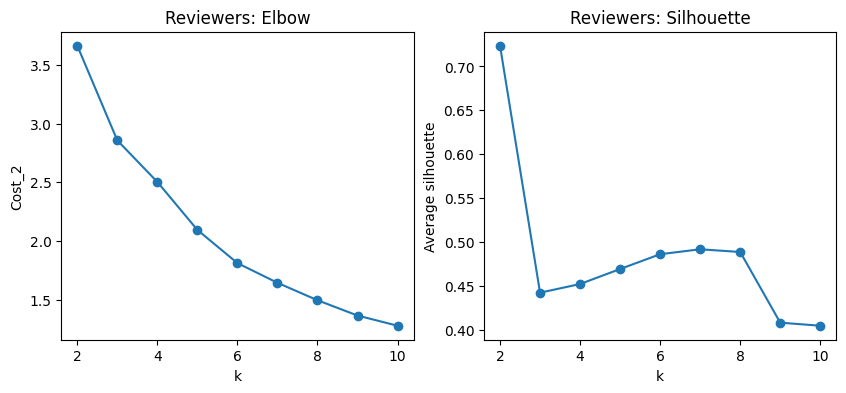

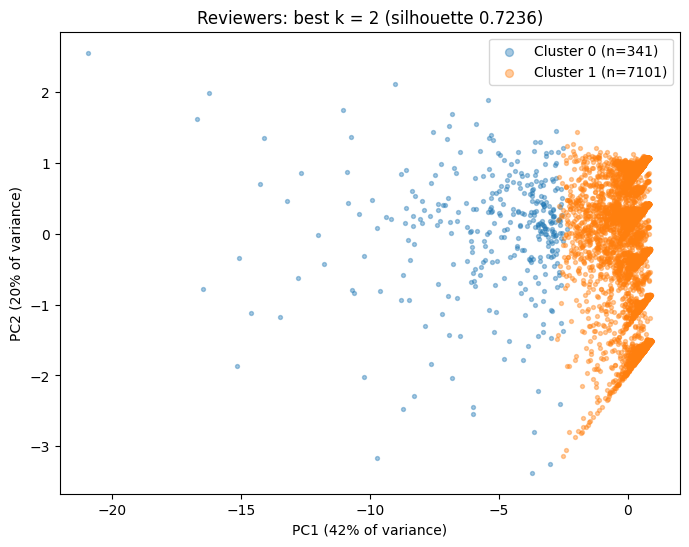

In [11]:
print("Reviewers:\n")

ks, costs_reviewers, silhouettes_reviewers, labels_reviewers = run_k_search(X, 3)

plot_k_search(ks, costs_reviewers, silhouettes_reviewers, 'Reviewers')
plot_best_clusters(X, ks, silhouettes_reviewers, labels_reviewers, 'Reviewers')   

Review text:

k= 2:
	Cost_2: 0.7676
	Silhouette: 0.0595
	Labels: [5599 4300]
k= 3:
	Cost_2: 0.7371
	Silhouette: 0.0600
	Labels: [4883 4391  625]
k= 4:
	Cost_2: 0.7230
	Silhouette: 0.0459
	Labels: [ 594 2528 3182 3595]
k= 5:
	Cost_2: 0.7121
	Silhouette: 0.0439
	Labels: [ 586 1593 1877 3009 2834]
k= 6:
	Cost_2: 0.7037
	Silhouette: 0.0444
	Labels: [ 536 1634 2735 1372 1388 2234]
k= 7:
	Cost_2: 0.6958
	Silhouette: 0.0465
	Labels: [ 524 1211 1402 1375 2494 1214 1679]
k= 8:
	Cost_2: 0.6898
	Silhouette: 0.0468
	Labels: [1121 1034  516 1276 2321 1103 1453 1075]
k= 9:
	Cost_2: 0.6851
	Silhouette: 0.0297
	Labels: [1433 1467  892 1014 1052  517 1402 1214  908]
k= 10:
	Cost_2: 0.6800
	Silhouette: 0.0328
	Labels: [1418 1452  512  916 1368  996 1016  896  100 1225]


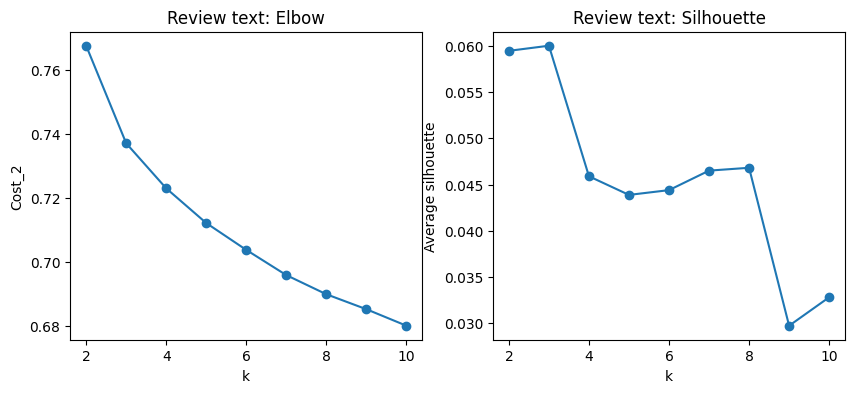

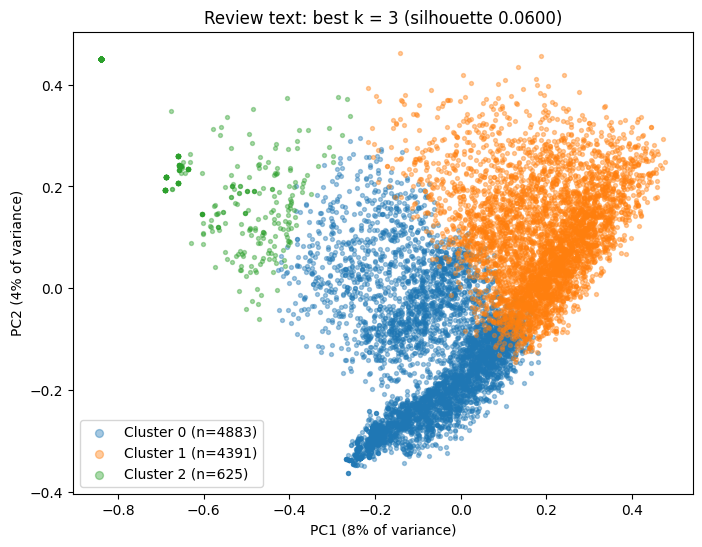

In [12]:
print("Review text:\n")

ks, costs_text, silhouettes_text, labels_text = run_k_search(X_text, 3)

plot_k_search(ks, costs_text, silhouettes_text, 'Review text')
plot_best_clusters(X_text, ks, silhouettes_text, labels_text, 'Review text') 